# Figure S7 — TLS marker expression within the Visium HD ROI

Source: `10x_tmp/wt_mature.ipynb`; Supplementary Information, page 13.
ROI: x in [0, 4000], y in [6000, 10000], including boundaries in the original spatial coordinates.
Gene order: TRAC, MS4A1, CD3D, CCL19, CXCL13 and FCER2.
Read only the required genes; do not retrain, recluster or redefine the ROI.

The source applies log1p when the full matrix X.max()>100; it does not call normalize_total.
The default `EXPRESSION_MODE='source_auto'` preserves this rule. If the input file has changed, explicitly choose
`'counts'` or `'log1p'` to avoid applying the transformation twice. No additional normalization is introduced.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [1]:
FIGURE = 'figS7'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
    'visium': '10x_tmp/WT.h5ad',
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
Data root: /home/zzj/lare
  OK visium: /home/zzj/lare/10x_tmp/WT.h5ad
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS7


In [2]:
import h5py
import scanpy as sc
import anndata as ad
SOURCE = DATA_PATHS['visium']
GENES = ['TRAC', 'MS4A1', 'CD3D', 'CCL19', 'CXCL13', 'FCER2']
X_RANGE, Y_RANGE = (0, 4000), (6000, 10000)
EXPRESSION_MODE = 'source_auto'  # 'source_auto', 'counts', or 'log1p'
metadata = read_metadata(SOURCE, obsm_keys=['spatial'])
coords = metadata.obsm['spatial']
roi = ((coords[:, 0] >= X_RANGE[0]) & (coords[:, 0] <= X_RANGE[1])
       & (coords[:, 1] >= Y_RANGE[0]) & (coords[:, 1] <= Y_RANGE[1]))
if not roi.any():
    raise ValueError('The specified ROI contains no spots')
expression = read_expression(SOURCE, GENES, row_mask=roi)
if EXPRESSION_MODE == 'source_auto':
    # Match the source condition against the entire matrix, not just these six genes.
    with h5py.File(require_file(SOURCE), 'r') as f:
        node = f['X']
        values = node['data'] if isinstance(node, h5py.Group) else node
        maximum = max(float(np.max(values[start:start + 4096])) for start in range(0, len(values), 4096))
    apply_log1p = maximum > 100
elif EXPRESSION_MODE in {'counts', 'log1p'}:
    apply_log1p = EXPRESSION_MODE == 'counts'
else:
    raise ValueError('Unknown EXPRESSION_MODE')
if np.any(expression < 0):
    raise ValueError('Expected nonnegative expression values')
if apply_log1p:
    expression = np.log1p(expression)
roi_adata = ad.AnnData(X=expression, obs=metadata.obs.loc[roi].copy(), var=pd.DataFrame(index=GENES))
print(f'ROI spots: {roi_adata.n_obs}; log1p applied: {apply_log1p}')

ROI spots: 5659; log1p applied: True


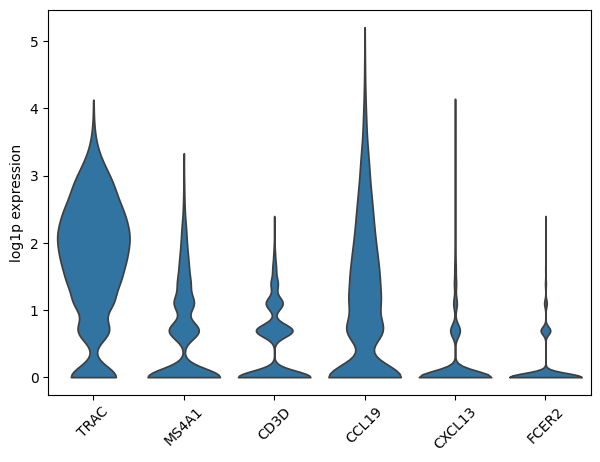

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
sc.pl.violin(roi_adata, keys=GENES, rotation=45, stripplot=False, show=False,
             use_raw=False, ax=ax)
ax.set_ylabel('log1p expression')
save_figure(fig, OUTPUT_DIR, 'figS7_tls_marker_violin')
pd.DataFrame(expression, index=roi_adata.obs_names, columns=GENES).to_csv(OUTPUT_DIR / 'figS7_roi_expression.csv')